In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/home-loan/train.csv
/kaggle/input/home-loan/test.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px 
import seaborn as sns

# Importer la base de donée

In [3]:
dt=pd.read_csv("/kaggle/input/home-loan/train.csv")

In [4]:
dt.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [5]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
dt.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
dt.shape

(614, 13)

# Remplacement des valeures manquantes 

* Nous allons  remplacer les variables manquantes categoriques par leurs  modes 
* Nous allons remplacer les variables manquantes numériques par la médiane 

In [8]:
def trans(data):
    for c in data.columns:
        if data[c].dtype=='int64' or data[c].dtype=='float64':
            data[c].fillna(data[c].median(),inplace=True)
        else:
              data[c].fillna(data[c].mode()[0],inplace=True)

In [9]:
trans(dt)

In [10]:
dt.isna().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

#   Analyse univariée

# Variables catégoriques

In [11]:
#dt["Loan_Status"].value_counts()
dt

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [12]:
dt["Loan_Status"].value_counts(normalize=True)*100

Y    68.729642
N    31.270358
Name: Loan_Status, dtype: float64

In [13]:
fig = px.histogram(dt, x="Loan_Status",title='Crédit accordé ou pas', color="Loan_Status",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [14]:
#Variable categorique 


In [15]:
#Genre
fig = px.histogram(dt, x="Gender",title='Genre',color="Gender",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [16]:
dt["Gender"].value_counts(normalize=True)*100

Male      81.758958
Female    18.241042
Name: Gender, dtype: float64

In [17]:
#Married
fig = px.histogram(dt, x="Married",title='Married',color="Married",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [18]:
dt["Married"].value_counts(normalize=True)*100

Yes    65.309446
No     34.690554
Name: Married, dtype: float64

In [19]:
#Dependents           
fig = px.histogram(dt, x="Dependents",title='Dependents',color="Dependents",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [20]:
fig = px.pie(dt, names="Dependents",title='Dependents',color="Dependents",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [21]:
#Education
fig = px.histogram(dt, x="Education",title='Education',color="Education",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [22]:
dt["Education"].value_counts(normalize=True)*100

Graduate        78.175896
Not Graduate    21.824104
Name: Education, dtype: float64

In [23]:
#Self_Employed
fig = px.histogram(dt, x="Self_Employed",title='Self_Employed',color="Self_Employed",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [24]:
dt["Self_Employed"].value_counts(normalize=True)*100

No     86.644951
Yes    13.355049
Name: Self_Employed, dtype: float64

In [25]:
     
#Property_Area 
fig = px.histogram(dt, x="Property_Area",title='Property_Area',color="Property_Area",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

In [26]:
fig = px.pie(dt, names="Property_Area",title='Property_Area',color="Property_Area",template= 'plotly_dark')
fig.show(font = dict(size=17,family="Franklin Gothic"))

# Variables Numériques

In [27]:
var_num=["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term"]


In [28]:
dt[var_num].describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
count,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,145.752443,342.410423
std,6109.041673,2926.248369,84.107233,64.428629
min,150.000000,0.000000,9.000000,12.000000
25%,2877.500000,0.000000,100.250000,360.000000
50%,3812.500000,1188.500000,128.000000,360.000000
75%,5795.000000,2297.250000,164.750000,360.000000
max,81000.000000,41667.000000,700.000000,480.000000


In [29]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [30]:
#ApplicantIncome
fig = px.histogram(dt, x="ApplicantIncome", facet_col="Loan_Status",
                  marginal="box",color="Loan_Status")
fig.show()

In [31]:
#CoapplicantIncome
fig = px.histogram(dt, x="CoapplicantIncome", facet_col="Loan_Status",
                  marginal="box",color="Loan_Status")
fig.show()

In [32]:
#LoanAmount
fig = px.histogram(dt, x="LoanAmount", facet_col="Loan_Status",
                  marginal="box",color="Loan_Status")
fig.show()

# Analyse bivariée

In [33]:
dt['Credit_History'] = dt['Credit_History'].replace(1.0,'Yes')
dt['Credit_History'] = dt['Credit_History'].replace(0.0,'No')
#Les variables categoriques
var_cat=["Loan_Status","Gender","Married","Dependents","Education","Self_Employed","Property_Area","Credit_History"]


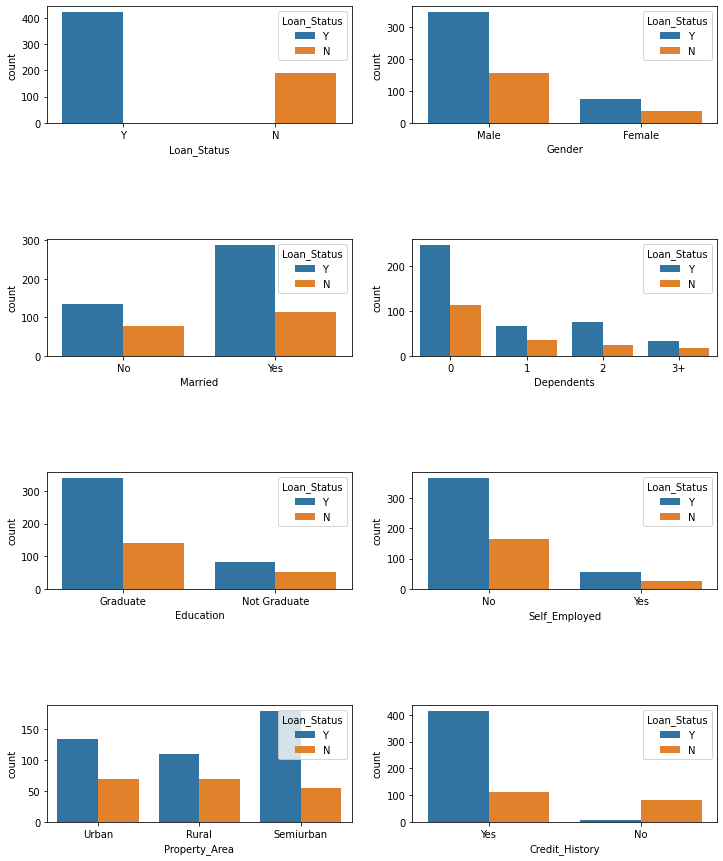

In [34]:
fig,axes=plt.subplots(4,2,figsize=(12,15))
for idx ,cat_col in enumerate(var_cat):
    row , col = idx//2 ,idx%2
    sns.countplot(x=cat_col,data=dt,hue="Loan_Status",ax=axes[row,col])
   
plt.subplots_adjust(hspace=1)

# Correlation des Variables numériques

<AxesSubplot:>

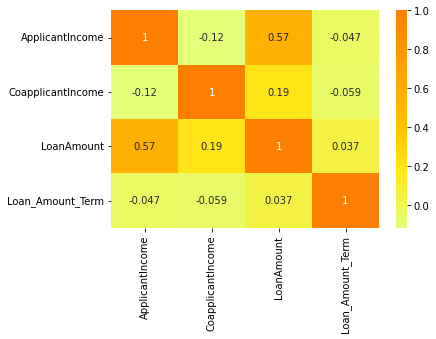

In [35]:
sns.heatmap(dt.corr(),cmap = 'Wistia', annot= True)

# Création du modele 

In [36]:
dt_num=dt[var_num]
dt_cat=dt[var_cat]
dt_cat

,Loan_Status,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Credit_History
0,Y,Male,No,0,Graduate,No,Urban,Yes
1,N,Male,Yes,1,Graduate,No,Rural,Yes
2,Y,Male,Yes,0,Graduate,Yes,Urban,Yes
3,Y,Male,Yes,0,Not Graduate,No,Urban,Yes
4,Y,Male,No,0,Graduate,No,Urban,Yes
...,...,...,...,...,...,...,...,...
609,Y,Female,No,0,Graduate,No,Rural,Yes
610,Y,Male,Yes,3+,Graduate,No,Rural,Yes
611,Y,Male,Yes,1,Graduate,No,Urban,Yes
612,Y,Male,Yes,2,Graduate,No,Urban,Yes


In [37]:
dt_cat=pd.get_dummies(dt_cat,drop_first=True)
dt_cat

,Loan_Status_Y,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Credit_History_Yes
0,1,1,0,0,0,0,0,0,0,1,1
1,0,1,1,1,0,0,0,0,0,0,1
2,1,1,1,0,0,0,0,1,0,1,1
3,1,1,1,0,0,0,1,0,0,1,1
4,1,1,0,0,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
609,1,0,0,0,0,0,0,0,0,0,1
610,1,1,1,0,0,1,0,0,0,0,1
611,1,1,1,1,0,0,0,0,0,1,1
612,1,1,1,0,1,0,0,0,0,1,1


In [38]:
dt_encoded=pd.concat([dt_cat,dt_num],axis=1)
dt_encoded

,Loan_Status_Y,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Credit_History_Yes,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,1,1,0,0,0,0,0,0,0,1,1,5849,0.0,128.0,360.0
1,0,1,1,1,0,0,0,0,0,0,1,4583,1508.0,128.0,360.0
2,1,1,1,0,0,0,0,1,0,1,1,3000,0.0,66.0,360.0
3,1,1,1,0,0,0,1,0,0,1,1,2583,2358.0,120.0,360.0
4,1,1,0,0,0,0,0,0,0,1,1,6000,0.0,141.0,360.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,1,0,0,0,0,0,0,0,0,0,1,2900,0.0,71.0,360.0
610,1,1,1,0,0,1,0,0,0,0,1,4106,0.0,40.0,180.0
611,1,1,1,1,0,0,0,0,0,1,1,8072,240.0,253.0,360.0
612,1,1,1,0,1,0,0,0,0,1,1,7583,0.0,187.0,360.0


In [39]:
y=dt_encoded["Loan_Status_Y"]
y

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status_Y, Length: 614, dtype: uint8

In [40]:
x=dt_encoded.drop("Loan_Status_Y",axis=1)
x

,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Credit_History_Yes,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,1,0,0,0,0,0,0,0,1,1,5849,0.0,128.0,360.0
1,1,1,1,0,0,0,0,0,0,1,4583,1508.0,128.0,360.0
2,1,1,0,0,0,0,1,0,1,1,3000,0.0,66.0,360.0
3,1,1,0,0,0,1,0,0,1,1,2583,2358.0,120.0,360.0
4,1,0,0,0,0,0,0,0,1,1,6000,0.0,141.0,360.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,0,0,0,0,1,2900,0.0,71.0,360.0
610,1,1,0,0,1,0,0,0,0,1,4106,0.0,40.0,180.0
611,1,1,1,0,0,0,0,0,1,1,8072,240.0,253.0,360.0
612,1,1,0,1,0,0,0,0,1,1,7583,0.0,187.0,360.0


In [41]:
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score



In [42]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=3)

In [43]:
model=LogisticRegression()
model.fit(x_train,y_train)
print("Votre Intelligence Arti est fiable à")
print(model.score(x_test,y_test)*100),print("%")

Votre Intelligence Arti est fiable à
85.36585365853658
%


(None, None)